# Dendrograma jerárquico

**Proyecto BI – Purchasing (AdventureWorks2025)**

**Entradas:**  
- `data/processed/purchasing_clustering_final.csv`  
- `data/processed/purchasing_segmentos_kmeans.csv`

**Objetivo:** Aplicar análisis jerárquico a los proveedores segmentados con K-Means.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

ROOT = Path('..') if Path('../data').exists() else Path('.')
PROC = ROOT / 'data/processed'

df_clust = pd.read_csv(PROC / 'purchasing_clustering_final.csv')
df_seg   = pd.read_csv(PROC / 'purchasing_segmentos_kmeans.csv')

df = df_clust.merge(df_seg[['VendorID', 'Cluster', 'Segmento']], on='VendorID', how='left')

print(f'Filas tras merge: {len(df)}')
print(f'Proveedores únicos: {df["VendorID"].nunique()}')
df.head()

Filas tras merge: 88
Proveedores únicos: 88


,VendorID,NombreProveedor,ValorTotalOrdenes,NumeroOrdenes,ValorTotalOrdenes_log,ValorTotalOrdenes_z,NumeroOrdenes_z,Cluster,Segmento
0,1492,Australia Bike Retailer,"32,058.99",54.00,10.38,-0.56,0.56,1,Pequeños recurrentes
1,1494,Allenson Cycles,"498,589.59",51.00,13.12,0.52,0.36,2,Grandes recurrentes
2,1496,Advanced Bicycles,"28,502.09",51.00,10.26,-0.61,0.36,1,Pequeños recurrentes
3,1498,"Trikes, Inc.","1,461,653.95",50.00,14.20,0.95,0.29,2,Grandes recurrentes
4,1500,Morgan Bike Accessories,"23,146.99",50.00,10.05,-0.69,0.29,1,Pequeños recurrentes


## 1. Población y datos de entrada

**Población:** 88 proveedores con al menos una orden de compra (se excluyeron 18 sin órdenes).

**Variables:** `ValorTotalOrdenes_z` y `NumeroOrdenes_z` (mismas variables usadas en K-Means).

**Decisión sobre 1699 y 1700:**
- `1699` – Distribuidora Ejemplo S.A. (3 órdenes, $83.10)
- `1700` – garfield (1 orden, $17.00)

Se incluyen por cumplir el criterio >= 1 orden y mantener consistencia con la población de clustering.

In [2]:
print('Conteo por fuente:')
print(f'- df_clust: {len(df_clust)}')
print(f'- df_seg:   {len(df_seg)}')
print(f'- df unida: {len(df)}')
print()

casos = df[df['VendorID'].isin([1699, 1700])][['VendorID','NombreProveedor','ValorTotalOrdenes','NumeroOrdenes','ValorTotalOrdenes_z','NumeroOrdenes_z','Cluster','Segmento']]
display(casos)
print()
print('Justificación: incluidos (>=1 orden). Se mantienen en los 88 para comparar con la segmentación K-Means.')

Conteo por fuente:
- df_clust: 88
- df_seg:   88
- df unida: 88



,VendorID,NombreProveedor,ValorTotalOrdenes,NumeroOrdenes,ValorTotalOrdenes_z,NumeroOrdenes_z,Cluster,Segmento
86,1699,Distribuidora Ejemplo S.A.,83.10,3.00,-2.91,-2.88,0,Ocasionales
87,1700,garfield,17.00,1.00,-3.52,-3.01,0,Ocasionales



Justificación: incluidos (>=1 orden). Se mantienen en los 88 para comparar con la segmentación K-Means.


In [3]:
FEATURES_H = ['ValorTotalOrdenes_z', 'NumeroOrdenes_z']
X_h = df[FEATURES_H].copy()
labels_prov = df['VendorID'].astype(str) + ' - ' + df['NombreProveedor'].astype(str)

print('Shape X_h:', X_h.shape)
X_h.describe().T

Shape X_h: (88, 2)


,count,mean,std,min,25%,50%,75%,max
ValorTotalOrdenes_z,88.00,-0.00,1.01,-3.52,-0.65,-0.11,0.95,1.44
NumeroOrdenes_z,88.00,-0.00,1.01,-3.01,0.29,0.36,0.36,0.56


## 2. Comparación de métodos de enlace

Se comparan **Ward**, **average** y **complete** con distancia euclidiana usando el coeficiente cofenético.

In [4]:
methods = ['ward', 'average', 'complete']
results = []
Z_dict = {}

for m in methods:
    Z = linkage(X_h, method=m, metric='euclidean')
    Z_dict[m] = Z
    dists = pdist(X_h, metric='euclidean')
    c, _ = cophenet(Z, dists)
    results.append({'Método': m, 'Coeficiente cofenético': c})

df_coph = pd.DataFrame(results).sort_values('Coeficiente cofenético', ascending=False).reset_index(drop=True)
display(df_coph)

best_method = df_coph.iloc[0]['Método']
print(f'\nMétodo elegido (mayor coeficiente cofenético): {best_method}')

,Método,Coeficiente cofenético
0,average,0.94
1,complete,0.91
2,ward,0.85



Método elegido (mayor coeficiente cofenético): average


## 3. Dendrograma completo y truncado (coloreado por cluster K-Means)

In [5]:
Z_best = Z_dict[best_method]

clusters_vals = sorted(df['Cluster'].dropna().unique())
palette = sns.color_palette('tab10', n_colors=len(clusters_vals))
cluster_to_color = {c: palette[i] for i,c in enumerate(clusters_vals)}

print('Mapeo Cluster -> color:')
for k,v in cluster_to_color.items():
    print(f'  Cluster {k}')

Mapeo Cluster -> color:
  Cluster 0
  Cluster 1
  Cluster 2


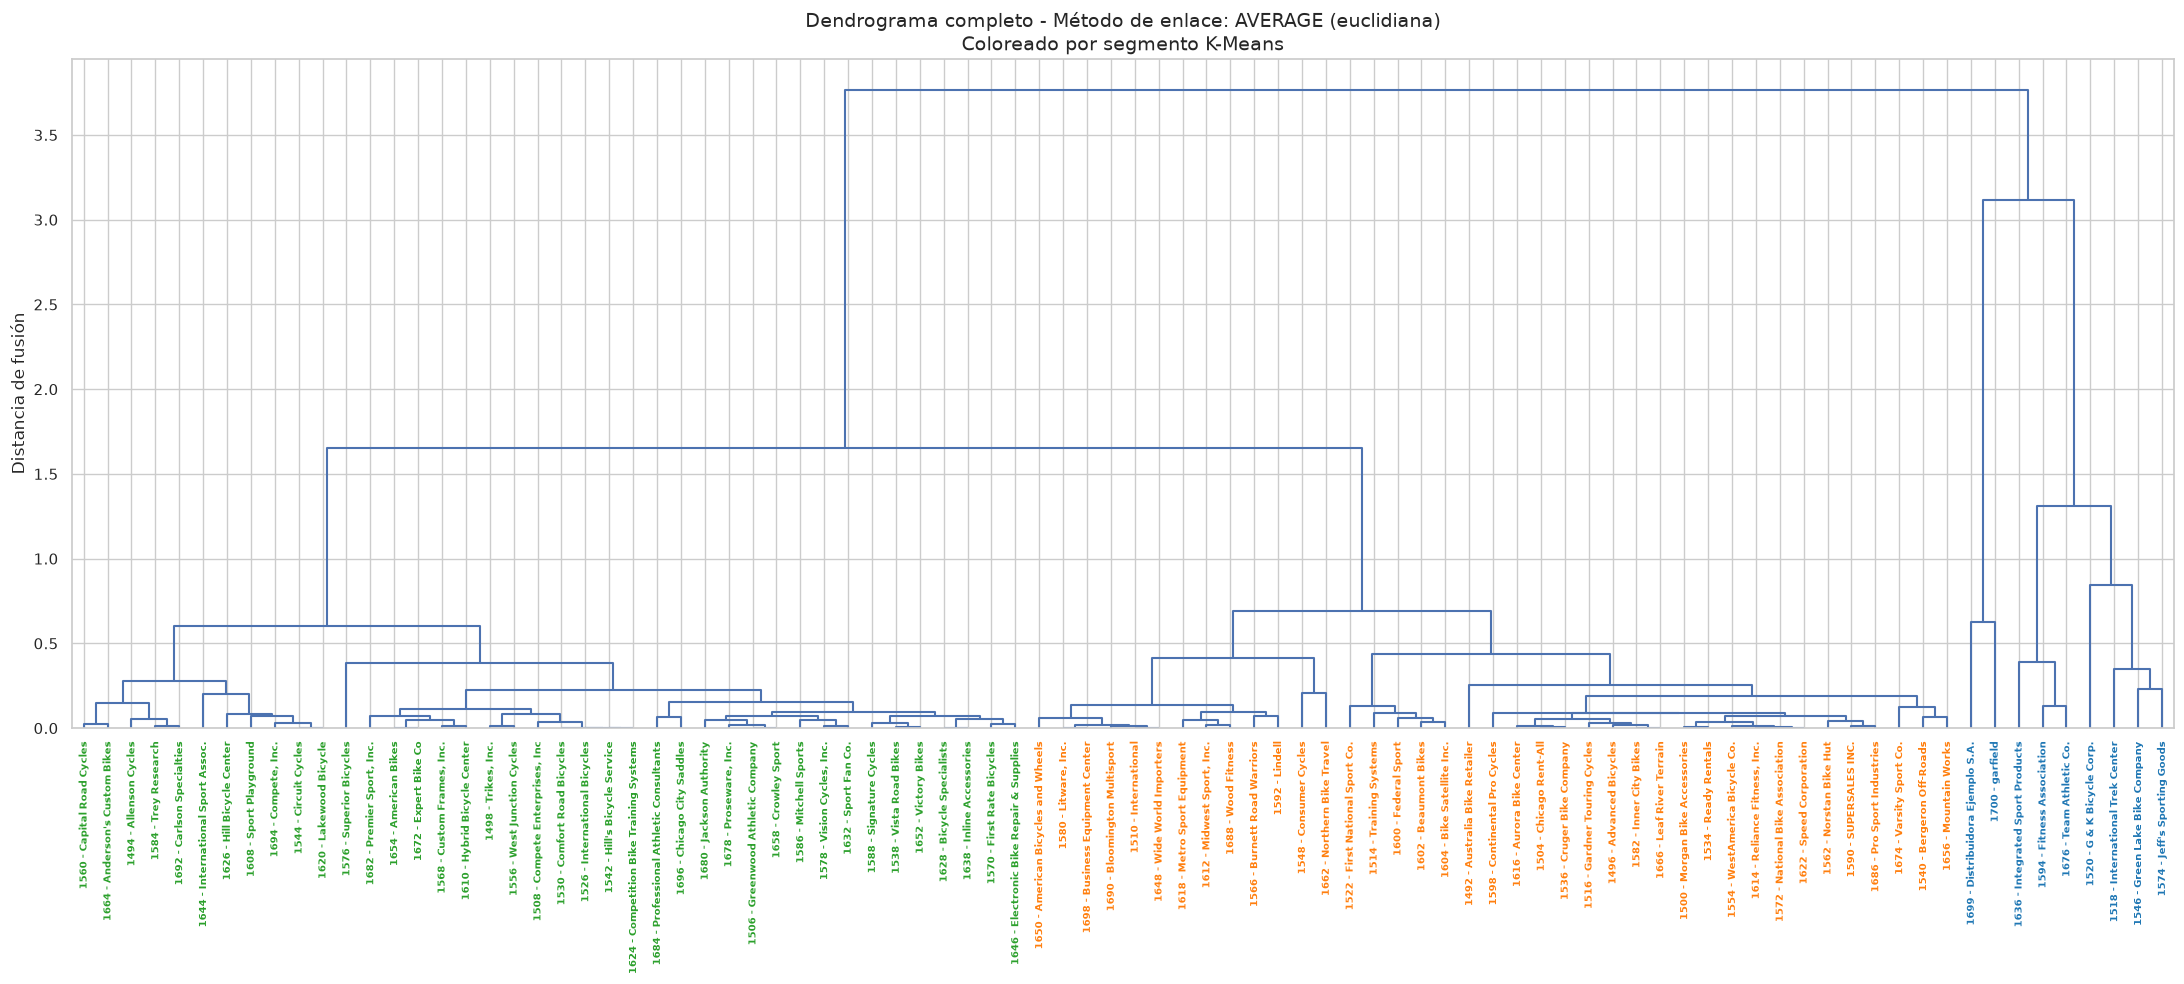

In [6]:
plt.figure(figsize=(22, 10))
dendrogram(
    Z_best,
    labels=labels_prov.tolist(),
    leaf_rotation=90,
    leaf_font_size=7,
    color_threshold=0
)
ax = plt.gca()
for lbl in ax.get_xticklabels():
    txt = lbl.get_text()
    if '-' in txt:
        try:
            vid = int(txt.split(' - ')[0])
            c = df[df['VendorID']==vid]['Cluster'].values[0]
            lbl.set_color(cluster_to_color[c])
            lbl.set_fontweight('bold')
        except:
            pass

plt.title(f'Dendrograma completo - Método de enlace: {best_method.upper()} (euclidiana)\nColoreado por segmento K-Means', fontsize=14)
plt.ylabel('Distancia de fusión')
plt.tight_layout()
plt.show()

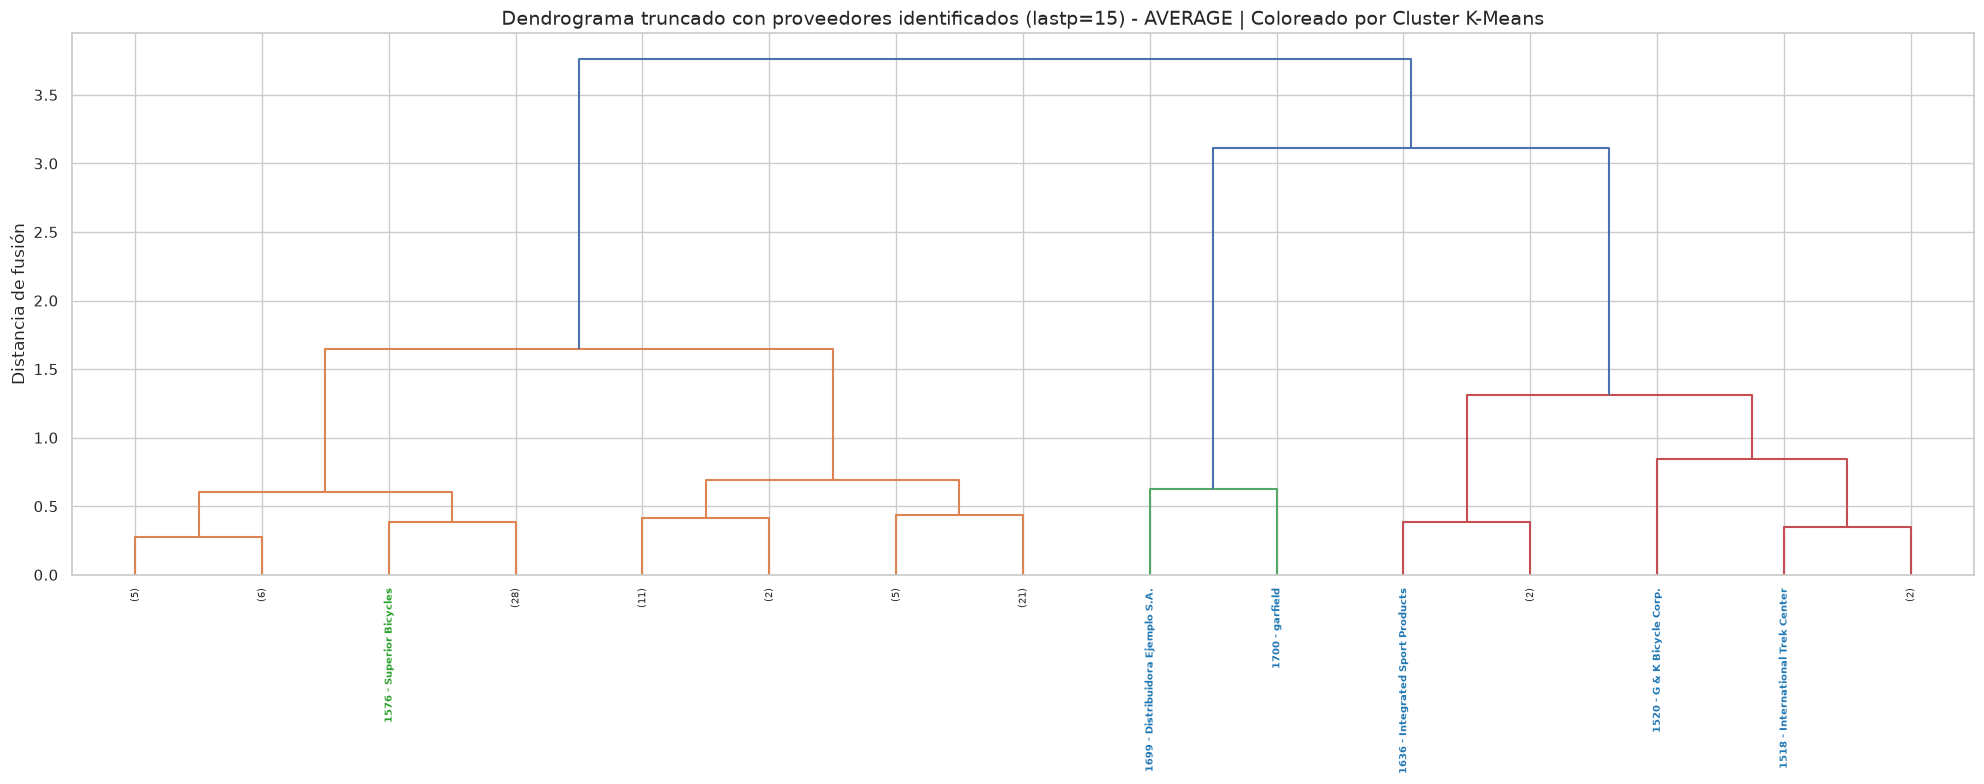

In [7]:
plt.figure(figsize=(20, 8))
dendrogram(
    Z_best,
    truncate_mode='lastp',
    p=15,
    labels=labels_prov.tolist(),
    leaf_rotation=90,
    leaf_font_size=7,
)
ax = plt.gca()
for lbl in ax.get_xticklabels():
    txt = lbl.get_text()
    if '-' in txt:
        try:
            vid = int(txt.split(' - ')[0])
            c = df[df['VendorID']==vid]['Cluster'].values[0]
            lbl.set_color(cluster_to_color[c])
            lbl.set_fontweight('bold')
        except:
            pass
plt.title(f'Dendrograma truncado con proveedores identificados (lastp=15) - {best_method.upper()} | Coloreado por Cluster K-Means', fontsize=14)
plt.ylabel('Distancia de fusión')
plt.tight_layout()
plt.show()

## 4. Punto de corte a partir de distancias de fusión

,Paso,Distancia_fusion,Delta,Delta_rel
72,73,0.25,0.02,0.10
73,74,0.28,0.02,0.09
74,75,0.35,0.07,0.26
75,76,0.38,0.03,0.10
76,77,0.39,0.01,0.01
77,78,0.41,0.02,0.06
78,79,0.44,0.03,0.07
79,80,0.60,0.16,0.37
80,81,0.62,0.02,0.03
81,82,0.69,0.07,0.11


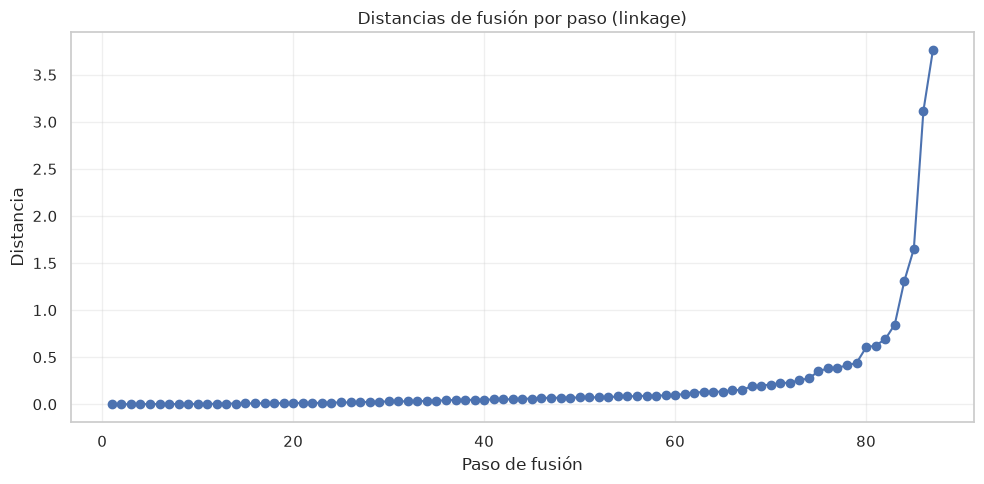

In [8]:
fusions = Z_best[:, 2]
df_fus = pd.DataFrame({
    'Paso': range(1, len(fusions)+1),
    'Distancia_fusion': fusions
})
df_fus['Delta'] = df_fus['Distancia_fusion'].diff()
df_fus['Delta_rel'] = df_fus['Delta'] / df_fus['Distancia_fusion'].shift(1)
display(df_fus.tail(15))

plt.figure(figsize=(10,5))
plt.plot(df_fus['Paso'], df_fus['Distancia_fusion'], marker='o')
plt.title('Distancias de fusión por paso (linkage)')
plt.xlabel('Paso de fusión')
plt.ylabel('Distancia')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
idx_jump = df_fus['Delta_rel'].idxmax()
t_suggest = df_fus.loc[idx_jump, 'Distancia_fusion'] * 0.98
print(f'Mayor salto relativo en paso {idx_jump+1} (dist fusión ~ {df_fus.loc[idx_jump,"Distancia_fusion"]:.3f})')
print(f'Threshold sugerido: {t_suggest:.3f}')

THRESHOLD_CORTE = t_suggest
df['Cluster_H'] = fcluster(Z_best, t=THRESHOLD_CORTE, criterion='distance')

print(f'\nPunto de corte (threshold): {THRESHOLD_CORTE:.4f}')
print(f'Número de clusters resultante (jerárquico): {df["Cluster_H"].nunique()}')
print()
print('Distribución por cluster jerárquico:')
display(df['Cluster_H'].value_counts().sort_index().to_frame('n'))
print()
print('Comparación con K-Means (tabla cruzada):')
ct = pd.crosstab(df['Cluster_H'], df['Cluster'], margins=True)
display(ct)

Mayor salto relativo en paso 3 (dist fusión ~ 0.001)
Threshold sugerido: 0.001

Punto de corte (threshold): 0.0006
Número de clusters resultante (jerárquico): 86

Distribución por cluster jerárquico:


,n
Cluster_H,
1,1
2,1
3,1
4,1
5,1
...,...
82,1
83,1
84,1



Comparación con K-Means (tabla cruzada):


Cluster,0,1,2,All
Cluster_H,,,,
1,0,0,1,1
2,0,0,1,1
3,0,0,1,1
4,0,0,1,1
5,0,0,1,1
...,...,...,...,...
83,1,0,0,1
84,1,0,0,1
85,1,0,0,1


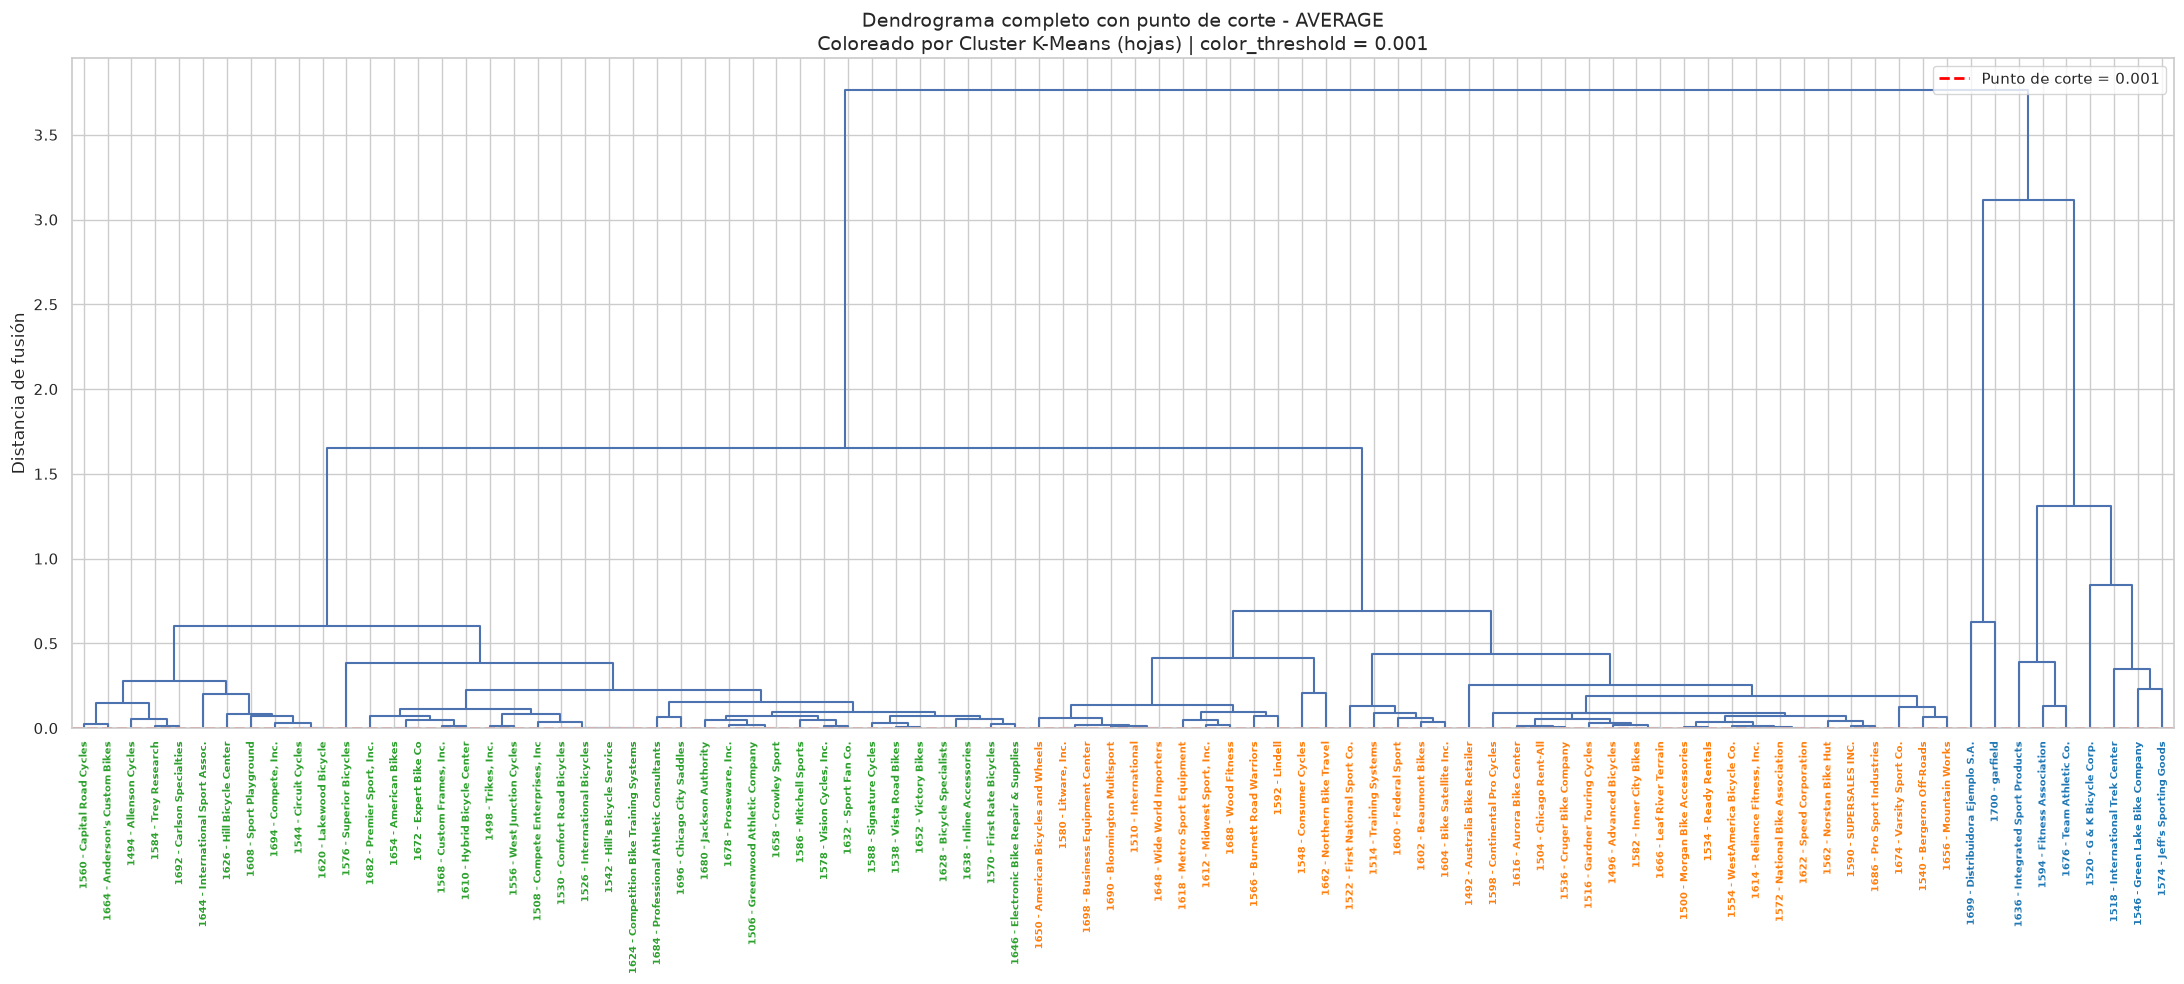

In [10]:
plt.figure(figsize=(22, 10))
dendrogram(
    Z_best,
    labels=labels_prov.tolist(),
    leaf_rotation=90,
    leaf_font_size=7,
    color_threshold=THRESHOLD_CORTE
)
ax = plt.gca()
for lbl in ax.get_xticklabels():
    txt = lbl.get_text()
    if '-' in txt:
        try:
            vid = int(txt.split(' - ')[0])
            c = df[df['VendorID']==vid]['Cluster'].values[0]
            lbl.set_color(cluster_to_color[c])
            lbl.set_fontweight('bold')
        except:
            pass

plt.axhline(y=THRESHOLD_CORTE, color='red', linestyle='--', linewidth=2, label=f'Punto de corte = {THRESHOLD_CORTE:.3f}')
plt.title(f'Dendrograma completo con punto de corte - {best_method.upper()}\nColoreado por Cluster K-Means (hojas) | color_threshold = {THRESHOLD_CORTE:.3f}', fontsize=14)
plt.ylabel('Distancia de fusión')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Resultados

- Se define la población (88 proveedores) e incluye a 1699 y 1700.
- Se compara Ward, average y complete con el coeficiente cofenético y se selecciona el mejor.
- Se generan dendrograma completo y truncado, con proveedores identificados y coloreados por cluster K-Means.
- Se define punto de corte a partir de las distancias de fusión y se obtiene el número de clusters jerárquicos.